# Energía y velocidad de los muones: qué se puede sacar de lo que medimos

Ninguna de las mediciones da la energía muón por muón (ver la sección 7 de
`decaimientos.ipynb`: por encima de ~300 MeV todos dejan lo mismo en una barra). Lo que
sí hay son tres datos que, juntos, fijan una distribución:

| medición | qué aporta |
|---|---|
| muones que **frenan** en el centellador 3 (corridas de decaimientos) | cuántos muones hay en una franja angosta de energía baja (~90 MeV): un punto absoluto del espectro |
| **barrido angular** (`tasa_vs_angulo.ipynb`) | el exponente con que cae el espectro a energías altas |
| **tiempo de vuelo** (`filtrado_muones.ipynb`) | la velocidad media, como chequeo |

Con eso se ajusta el modelo más simple que describe el espectro a nivel del mar,
$\,dN/dE \propto (E_0 + E)^{-n}$ (Shukla y Sankrith, arXiv:1606.06907): $n$ sale del barrido
angular y $E_0$ de la fracción de muones que frenan. Es una **estimación con un modelo**:
los datos fijan sus dos parámetros, pero la forma de la curva entre 0,1 y 100 GeV es la
del modelo, no algo que hayamos medido punto por punto.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import decaimientos as dec

plt.style.use("seaborn-v0_8")
plt.rcParams.update({"font.family": "serif", "font.size": 14, "axes.labelsize": 14, "xtick.labelsize": 14,
                     "ytick.labelsize": 14, "legend.fontsize": 14, "mathtext.default": "regular",
                     "mathtext.fontset": "cm", "legend.frameon": True, "figure.dpi": 80})
CARPETA_SALIDA = Path("../salida_decaimientos")
rng = np.random.default_rng(1)

ev = dec.indexar()
tab = dec.tabla_eventos(ev)
filtros = dec.armar_filtros(tab)                       # mismos cortes que decaimientos.ipynb
ACTIVOS = ["traza limpia", "entrada en u1", "hay pulso tardio", "amplitud tardio",
           "dt en rango", "ancho tardio", "sin pulsos extra", "sin pulsos previos"]
sel = dec.combinar(filtros, ACTIVOS)
limpio = dec.combinar(filtros, ["traza limpia", "entrada en u1"])
pasante = limpio & ~tab["hay_tardio"].to_numpy() & (tab["a_antes"].to_numpy() == 0)
patron = tab["patron_ent"].to_numpy()

## 1. Cuántos muones frenan en el centellador 3

Se usa solo la clase más limpia: muones que dieron pulso en los tres centelladores y cuyo
electrón aparece en `u3`. Frenaron en plástico (no en el hierro), en una barra de espesor
conocido. Para pasar de «decaimientos vistos» a «muones que frenaron» hacen falta tres
eficiencias.

### a) Ventana temporal

Solo se aceptan decaimientos con $\Delta t$ entre 100 y 1400 ns, y una parte de los
$\mu^-$ es capturada por el carbono sin decaer.

In [2]:
A_DT, B_DT = 100.0, 1400.0
F_MAS = 0.56                                        # fracción de mu+ (cociente mu+/mu- ~ 1,27)
ventana = lambda tau: np.exp(-A_DT / tau) - np.exp(-B_DT / tau)
ef_ventana = F_MAS * ventana(dec.TAU_MU) + (1 - F_MAS) * 0.924 * ventana(dec.TAU_MU_C)
print(f"eficiencia de la ventana temporal: {ef_ventana:.3f}")

eficiencia de la ventana temporal: 0.422


### b) Que el electrón supere los 60 mV

El electrón nace en un punto cualquiera de la barra, sale en una dirección cualquiera y
casi siempre se escapa: deja ~2 MeV por cm recorrido, no su energía entera. Un Monte
Carlo geométrico (punto uniforme en la barra de 4,5 × 4,5 × 46 cm, dirección isótropa,
energía del espectro de Michel) da la distribución de energía depositada. La única
incógnita es la escala mV/MeV, que se ajusta a la forma del espectro medido de amplitudes
del pulso tardío (bajando el corte a 30 mV para ver más espectro).

In [3]:
M = 400_000
lados = np.array([4.5, 4.5, 46.0])
origen = rng.uniform(0, 1, (M, 3)) * lados
u = rng.normal(size=(M, 3))
u /= np.linalg.norm(u, axis=1, keepdims=True)
with np.errstate(divide="ignore", invalid="ignore"):
    camino = np.where(u > 0, (lados - origen) / u, np.where(u < 0, -origen / u, np.inf)).min(axis=1)   # cm hasta salir
x = rng.uniform(0, 1, 4 * M)
x = x[rng.uniform(0, 1, 4 * M) < x ** 2 * (3 - 2 * x)][:M]            # espectro de Michel
deposito = np.minimum(52.8 * x, 2.0 * dec.PLASTICO["rho"] * camino)    # MeV
ruido = rng.normal(1, 0.2, M)                                          # resolución en amplitud (~20 %)

# datos: electrones en u3 de muones que frenaron en u3, con el corte de amplitud en 30 mV
filtros30 = dec.armar_filtros(tab, a_tardio_min=30)
frena_u3 = (tab["frena_en"].to_numpy() == 3) & tab["tardio_en_freno"].to_numpy()
a_e = tab.loc[dec.combinar(filtros30, ACTIVOS) & frena_u3, "a_tar_u3"].to_numpy(float)

bordes = np.arange(50, 260, 15)
n_dat = np.histogram(a_e, bordes)[0]
def modelo_e(escala):
    return np.histogram(deposito * escala * ruido, bordes)[0] / M
def chi2(escala):
    m = modelo_e(escala) * n_dat.sum() / modelo_e(escala).sum()
    return ((n_dat - m) ** 2 / np.maximum(m, 1)).sum()
escalas = np.arange(5, 14, 0.125)
c2 = np.array([chi2(e) for e in escalas])
escala = escalas[c2.argmin()]
esc_lo, esc_hi = escalas[c2 <= c2.min() + 1][[0, -1]]
ef_e = lambda e: (deposito * e * ruido >= 60).mean()
escala_muones = 82.0 / float(dec.energia_depositada(2000.0))          # pico de los muones rápidos en u3
print(f"escala ajustada a los electrones: {escala:.2f} (+{esc_hi - escala:.2f} −{escala - esc_lo:.2f}) mV/MeV,  "
      f"chi2 = {c2.min():.1f} con {len(n_dat) - 2} grados de libertad")
print(f"escala que da el pico de los muones rápidos: {escala_muones:.2f} mV/MeV")
ef_electron = ef_e(escala)
err_ef_electron = 0.5 * (ef_e(max(esc_hi, escala * 1.1)) - ef_e(min(esc_lo, escala * 0.9)))
print(f"eficiencia del electrón (≥ 60 mV): {ef_electron:.3f} ± {err_ef_electron:.3f}")

escala ajustada a los electrones: 8.62 (+0.12 −0.50) mV/MeV,  chi2 = 11.1 con 11 grados de libertad
escala que da el pico de los muones rápidos: 8.13 mV/MeV
eficiencia del electrón (≥ 60 mV): 0.339 ± 0.050


Las dos escalas salen de cosas independientes (cuánto recorre un electrón que se escapa
y cuánto deja un muón que atraviesa) y coinciden: el espectro de los pulsos tardíos es el
de electrones de decaimiento, y la calibración mV → MeV cierra.

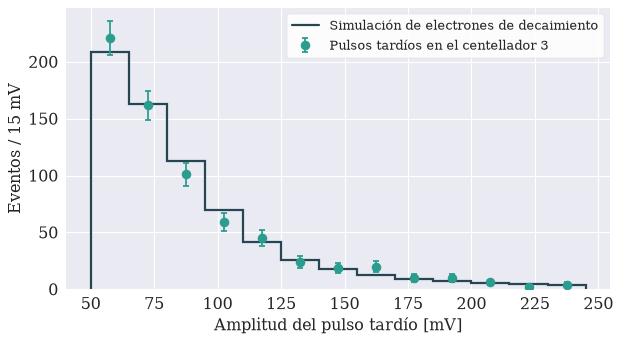

In [4]:
centro = 0.5 * (bordes[1:] + bordes[:-1])
m = modelo_e(escala)
m = m * n_dat.sum() / m.sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stairs(m, bordes, color=dec.COLOR_AJUSTE, lw=2, zorder=2, label="Simulación de electrones de decaimiento")
ax.errorbar(centro, n_dat, yerr=np.sqrt(n_dat), fmt="o", ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6,
            color=dec.COLOR_DATOS, mfc=dec.COLOR_DATOS, mec=dec.COLOR_DATOS, zorder=3, label="Pulsos tardíos en el centellador 3")
ax.set_xlabel("Amplitud del pulso tardío [mV]")
ax.set_ylabel(f"Eventos / {bordes[1] - bordes[0]} mV")
ax.set_ylim(0, None)
ax.legend(loc="upper right", facecolor="white", framealpha=0.9, fontsize=12)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "espectro_electron_u3.pdf", bbox_inches="tight")
fig.savefig(CARPETA_SALIDA / "espectro_electron_u3.png", bbox_inches="tight", dpi=300)

### c) Sesgo del umbral de disparo

El disparo exige ~100 mV en `u1` y la selección en línea lo mismo en `u2`, y ese umbral
cae en plena distribución de los muones rápidos. Los muones lentos dejan más, así que
pasan el umbral más seguido y quedan sobrerrepresentados. `u3` no participa del disparo:
su distribución de amplitudes (cruda) se usa como plantilla de la forma verdadera,
escalada a la ganancia de cada canal.

In [5]:
# amplitud cruda (sin suavizar) del pulso de entrada de cada canal
en_ventana = (ev.tini >= 180) & (ev.tini <= 260)
k = np.where(en_ventana, ev.amp, -np.inf).argmax(axis=2)
hay = en_ventana.any(axis=2)
cruda = np.stack([np.where(hay[:, c], ev.ampc[np.arange(len(ev)), c, k[:, c]], 0) for c in range(3)], axis=1)

p111 = pasante & (patron == "111")
plantilla = cruda[p111, 2]
def ef_umbral(ganancia, corte, factor=1.0):
    return (plantilla * ganancia * factor >= corte).mean()

canal = {}
for c in (0, 1):
    corte = np.percentile(cruda[p111, c], 0.5)              # dónde corta el umbral
    med = np.median(cruda[p111, c])
    g = brentq(lambda g: np.median((plantilla * g)[plantilla * g >= corte]) - med, 0.6, 3.0)
    canal[c] = (g, corte)
    print(f"u{c + 1}: corta en ~{corte:.0f} mV, ganancia {g:.2f} × la de u3, deja pasar el {100 * ef_umbral(g, corte):.0f} % de los muones rápidos")

# cuánto más dejan en u1 y u2 los muones que frenan en u3 (cociente de medianas)
frenan3 = sel & frena_u3 & (patron == "111")
coc = [np.median(tab.loc[frenan3, f"a_ent_{c}"]) / np.median(tab.loc[p111, f"a_ent_{c}"]) for c in ("u1", "u2")]
sesgo = np.prod([ef_umbral(*canal[c], coc[c]) / ef_umbral(*canal[c]) for c in (0, 1)])
print(f"los que frenan en u3 dejan {coc[0]:.2f}× en u1 y {coc[1]:.2f}× en u2  ->  pasan el umbral {sesgo:.2f} veces más seguido")

u1: corta en ~109 mV, ganancia 1.23 × la de u3, deja pasar el 76 % de los muones rápidos
u2: corta en ~93 mV, ganancia 1.21 × la de u3, deja pasar el 85 % de los muones rápidos
los que frenan en u3 dejan 1.10× en u1 y 1.27× en u2  ->  pasan el umbral 1.18 veces más seguido


### Fracción de muones que frenan

La franja de energía sale del alcance: los que frenan en `u3` son los que, al entrar a la
pila, tenían energía para llegar a `u3` pero no para cruzarlo. Dónde está `u3` en g/cm² se
lee de la amplitud en `u1` de esos mismos muones (sección 7 de `decaimientos.ipynb`), sin
usar el espesor del hierro.

In [6]:
n_frenan = int((frenan3 & (tab["a_tar_u3"].to_numpy() >= 60)).sum())
n_pasan = int(p111.sum())

# energía al entrar a la pila: alcance medio de la clase (mitad de u3) ± media barra
referencia = float(dec.energia_depositada(2000.0))
T_medio = float(dec.energia_desde_deposito(coc[0] * referencia))
R_medio = float(dec.alcance(T_medio))
media_barra = 0.5 * dec.ESPESOR_BARRA * dec.PLASTICO["rho"]
T_lo, T_hi = dec.energia_para_alcance(R_medio - media_barra), dec.energia_para_alcance(R_medio + media_barra)

fraccion = n_frenan / (ef_ventana * ef_electron * sesgo) / n_pasan
por_GeV = fraccion / ((T_hi - T_lo) / 1000)

# incertezas relativas: estadística, electrón, umbral (mitad de la corrección), ventana y ancho de la franja
err_rel = dict(estadística=1 / np.sqrt(n_frenan), electrón=err_ef_electron / ef_electron, umbral=0.5 * (sesgo - 1),
               ventana=0.03, franja=0.10)
err_total = np.sqrt(sum(v ** 2 for v in err_rel.values()))
print(f"{n_frenan} decaimientos con electrón en u3 sobre {n_pasan} muones que atraviesan los tres centelladores")
print(f"eficiencia total = {ef_ventana:.3f} × {ef_electron:.3f} × {sesgo:.2f} = {ef_ventana * ef_electron * sesgo:.3f}")
print(f"frenan en u3: {100 * fraccion:.2f} % de los muones, con energía entre {T_lo:.0f} y {T_hi:.0f} MeV al entrar a la pila")
print(f"-> {por_GeV:.2f} ± {por_GeV * err_total:.2f} de los muones por GeV, a {T_medio:.0f} MeV")
pd.Series(err_rel).mul(100).round(0).rename("incerteza [%]").to_frame().T

531 decaimientos con electrón en u3 sobre 503953 muones que atraviesan los tres centelladores
eficiencia total = 0.422 × 0.339 × 1.18 = 0.169
frenan en u3: 0.62 % de los muones, con energía entre 79 y 90 MeV al entrar a la pila
-> 0.57 ± 0.12 de los muones por GeV, a 85 MeV


,estadística,electrón,umbral,ventana,franja
incerteza [%],4.0,15.0,9.0,3.0,10.0


## 2. El espectro

Modelo: $\dfrac{dN}{dE} \propto (E_0 + E)^{-n}$, con $E$ la energía cinética al llegar al
detector. $E_0$ es la escala por debajo de la cual el espectro es chato (tiene que ver
con lo que pierden los muones al cruzar la atmósfera) y $n$ el exponente con que cae.

- **$n$**: en este modelo la intensidad cae con el ángulo cenital como $\cos^{\,n-1}\theta$.
  El barrido angular dio $\cos^{2{,}02 \pm 0{,}37}\theta$, o sea $n = 3{,}02 \pm 0{,}37$.
- **$E_0$**: la fracción de muones por unidad de energía a energía baja es
  $(n-1)\,(E_0+E)^{-n} / (E_0+E_{\min})^{-(n-1)}$, donde $E_{\min}$ es la energía mínima para
  atravesar toda la pila. Se despeja $E_0$ del valor medido.

In [7]:
N_ANG, ERR_N_ANG = 2.02, 0.37              # exponente del barrido angular (tasa_vs_angulo.ipynb, ajuste sin 15° N)
GeV = 1000.0

def E0_de(por_GeV, n, T=T_medio / GeV, Tmin=T_hi / GeV):
    "E0 [GeV] tal que la fracción por GeV a energía T (relativa a los muones con E > Tmin) sea la medida."
    g = lambda E0: (n - 1) * (E0 + T) ** (-n) / (E0 + Tmin) ** (-(n - 1)) - por_GeV
    return brentq(g, 0.05, 200)

def cuantil(q, E0, n):
    "Energía cinética [GeV] por debajo de la cual está la fracción q de los muones."
    return E0 * ((1 - q) ** (-1 / (n - 1)) - 1)

# propagación de incertezas: se sortean n y la fracción medida
K = 20000
n_s = np.clip(rng.normal(N_ANG + 1, ERR_N_ANG, K), 2.3, None)
f_s = por_GeV * np.exp(rng.normal(0, err_total, K))
E0_s = np.array([E0_de(f, n) for f, n in zip(f_s, n_s)])
mediana_s = cuantil(0.5, E0_s, n_s)
p = lambda x: np.percentile(x, [16, 50, 84])

n_fit, E0_fit = N_ANG + 1, E0_de(por_GeV, N_ANG + 1)
print(f"n  = {n_fit:.2f} ± {ERR_N_ANG:.2f}   (referencia: 3,01 en Tsukuba, 3,06 en Durham)")
print("E0 = {1:.1f} (+{2:.1f} −{0:.1f}) GeV   (referencia: 4,29 en Tsukuba, 3,87 en Durham)".format(
    p(E0_s)[1] - p(E0_s)[0], p(E0_s)[1], p(E0_s)[2] - p(E0_s)[1]))
print("energía mediana = {1:.1f} (+{2:.1f} −{0:.1f}) GeV".format(
    p(mediana_s)[1] - p(mediana_s)[0], p(mediana_s)[1], p(mediana_s)[2] - p(mediana_s)[1]))

n  = 3.02 ± 0.37   (referencia: 3,01 en Tsukuba, 3,06 en Durham)
E0 = 3.4 (+1.1 −0.9) GeV   (referencia: 4,29 en Tsukuba, 3,87 en Durham)
energía mediana = 1.4 (+0.3 −0.3) GeV


Figura: fracción de muones por GeV en función de la energía. El punto lleno es la medición
de la sección 1 (la barra horizontal es la franja de energía). El punto hueco es la misma
cuenta para los que frenan en `u2` o en el hierro: queda **por debajo** porque del hierro
se escapan menos electrones y casi todos los $\mu^-$ son capturados, así que es una cota
inferior y no entra en el ajuste. La curva de referencia es la parametrización de Shukla
y Sankrith para nivel del mar (Tsukuba), que ajustaron por encima de 0,5 GeV: por debajo
de eso es una extrapolación.

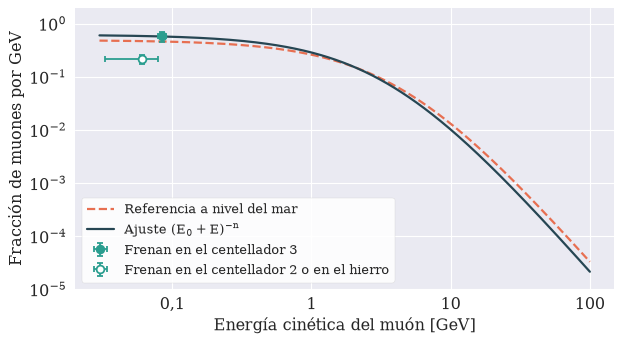

In [8]:
def espectro(T, E0, n, Tmin=T_hi / GeV):
    "Fracción de muones por GeV (normalizada a los que tienen E > Tmin)."
    return (n - 1) * (E0 + T) ** (-n) / (E0 + Tmin) ** (-(n - 1))

# cota inferior: los que frenan en u2 o en el hierro, con las mismas eficiencias que en plástico
frenan2 = sel & (tab["frena_en"].to_numpy() == 2) & (patron == "110")
coc2 = [np.median(tab.loc[frenan2, f"a_ent_{c}"]) / np.median(tab.loc[pasante & (patron == "110"), f"a_ent_{c}"]) for c in ("u1", "u2")]
sesgo2 = np.prod([ef_umbral(*canal[c], coc2[c]) / ef_umbral(*canal[c]) for c in (0, 1)])
T2_lo = float(dec.energia_para_alcance(2 * media_barra + 1.0))        # llega a u2 con energía para dar pulso
T2 = float(dec.energia_desde_deposito(coc2[0] * referencia))
por_GeV2 = frenan2.sum() / (ef_ventana * ef_electron * sesgo2) / int(pasante.sum()) / ((T_lo - T2_lo) / GeV)

T = np.geomspace(0.03, 100, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(T, espectro(T, 4.29, 3.01), color="#E76F51", lw=2, ls="--", zorder=2, label="Referencia a nivel del mar")
ax.plot(T, espectro(T, E0_fit, n_fit), color=dec.COLOR_AJUSTE, lw=2, zorder=2, label=r"Ajuste $(E_0 + E)^{-n}$")
c = dec.COLOR_DATOS
ax.errorbar(T_medio / GeV, por_GeV, yerr=por_GeV * err_total, xerr=[[(T_medio - T_lo) / GeV], [(T_hi - T_medio) / GeV]],
            fmt="o", ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, color=c, mfc=c, mec=c, zorder=3,
            label="Frenan en el centellador 3")
ax.errorbar(T2 / GeV, por_GeV2, yerr=por_GeV2 * err_total, xerr=[[(T2 - T2_lo) / GeV], [(T_lo - T2) / GeV]],
            fmt="o", ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, color=c, mfc="white", mec=c, zorder=3,
            label="Frenan en el centellador 2 o en el hierro")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.1, 1, 10, 100], ["0,1", "1", "10", "100"])
ax.set_xlabel("Energía cinética del muón [GeV]")
ax.set_ylabel("Fracción de muones por GeV")
ax.set_ylim(1e-5, 2)
ax.legend(loc="lower left", facecolor="white", framealpha=0.9, fontsize=12)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "espectro_energia_muones.pdf", bbox_inches="tight")
fig.savefig(CARPETA_SALIDA / "espectro_energia_muones.png", bbox_inches="tight", dpi=300)

## 3. Velocidades

Con el espectro ajustado, la velocidad sale de $\beta = \sqrt{1 - 1/\gamma^2}$,
$\gamma = 1 + E/m_\mu c^2$. La tabla da, para cada fracción de los muones, la energía y la
velocidad por debajo de las cuales está esa fracción (entre corchetes, el rango de 68 %
al variar $n$ y la fracción medida). La tabla arranca en el 5 % porque ahí está el
punto medido (~85 MeV): más abajo el espectro no está medido y el modelo solo extrapola.

In [9]:
def beta(T_GeV):
    g = 1 + np.asarray(T_GeV) * GeV / dec.M_MU
    return np.sqrt(1 - 1 / g ** 2)

filas = []
for q in (0.05, 0.10, 0.25, 0.50, 0.75, 0.90):
    Tq = cuantil(q, E0_s, n_s)
    lo, med, hi = p(Tq)
    filas.append({"fracción de los muones": f"{100 * q:.0f} % más lento", "energía cinética [GeV]": f"{med:.2f}  [{lo:.2f}, {hi:.2f}]",
                  "β = v/c": f"{beta(med):.4f}  [{beta(lo):.4f}, {beta(hi):.4f}]", "γ": f"{1 + med * GeV / dec.M_MU:.1f}"})
pd.DataFrame(filas).set_index("fracción de los muones")

,energía cinética [GeV],β = v/c,γ
fracción de los muones,,,
5 % más lento,"0.09 [0.07, 0.11]","0.8396 [0.8040, 0.8713]",1.8
10 % más lento,"0.19 [0.15, 0.23]","0.9316 [0.9106, 0.9487]",2.8
25 % más lento,"0.53 [0.43, 0.65]","0.9861 [0.9803, 0.9903]",6.0
50 % más lento,"1.42 [1.15, 1.76]","0.9976 [0.9964, 0.9984]",14.5
75 % más lento,"3.44 [2.77, 4.30]","0.9996 [0.9993, 0.9997]",33.6
90 % más lento,"7.48 [5.90, 9.59]","0.9999 [0.9998, 0.9999]",71.8


In [10]:
# chequeos con las otras mediciones
frac_lentos = 1 - (1 + (0.137 - 0) / E0_s) ** (-(n_s - 1))                # E < 137 MeV  <->  beta < 0,9
print("muones con β < 0,9: {1:.0f} % [{0:.0f}, {2:.0f}]".format(*(100 * p(frac_lentos))))

# velocidad de los que frenan, leída de lo que dejan en u1 (sección 7 de decaimientos.ipynb)
print(f"los que frenan en u3 entran a la pila con ~{T_medio:.0f} MeV: β = {beta(T_medio / GeV):.2f}")
print(f"los que frenan en u2 o en el hierro, con ~{T2:.0f} MeV: β = {beta(T2 / GeV):.2f}")

# tiempo de vuelo: filtrado_muones.ipynb (74 muones, d = 61,2 ± 1,4 cm, criterio CFD 50 %, sin corregir offset)
DT31, ERR_DT31, D13 = 2.41, 0.25, 0.612
c_luz = 0.299792458
# lo que predice el espectro para el promedio de 1/beta (muones con energía para cruzar las tres barras)
Tm = np.geomspace(0.045, 300, 4000)
peso = espectro(Tm, E0_fit, n_fit) * np.gradient(Tm)
inv_beta = (peso / beta(Tm)).sum() / peso.sum()
print(f"tiempo de vuelo medido: {DT31:.2f} ± {ERR_DT31:.2f} ns  ->  β = {D13 / c_luz / DT31:.2f} ± {D13 / c_luz / DT31 * ERR_DT31 / DT31:.2f} (sin el offset entre canales)")
print(f"tiempo de vuelo esperado con este espectro: {D13 / c_luz * inv_beta:.2f} ns  (β efectivo {1 / inv_beta:.3f})")

muones con β < 0,9: 8 % [6, 9]
los que frenan en u3 entran a la pila con ~85 MeV: β = 0.83
los que frenan en u2 o en el hierro, con ~61 MeV: β = 0.77
tiempo de vuelo medido: 2.41 ± 0.25 ns  ->  β = 0.85 ± 0.09 (sin el offset entre canales)
tiempo de vuelo esperado con este espectro: 2.08 ns  (β efectivo 0.980)


## Qué es medición y qué es modelo

- **Medido acá:** que ~0,6 % de los muones frena en una franja de ~10 MeV alrededor de
  90 MeV (±25 %); que los que frenan van a 0,77–0,83 $c$; que el exponente angular es
  $2{,}0 \pm 0{,}4$; que el tiempo de vuelo es compatible con $c$.
- **Modelo:** la forma $(E_0+E)^{-n}$ y la relación entre el exponente angular y $n$. Con
  eso los dos parámetros quedan fijados por nuestros datos y son compatibles con los de la
  bibliografía, pero la curva por encima de ~0,1 GeV no está medida punto por punto.
- **Lo que más pesa en el error:** la eficiencia para ver el electrón (±15–20 %) y el
  error de $n$. La mediana de energía depende poco de $n$; la media depende mucho (para
  $n$ cerca de 3 es $\approx E_0/(n-2)$) y por eso no se informa.
- **Lo que no se tuvo en cuenta:** el techo y las losas sobre el detector (frenan a los
  más lentos y corren $E_0$ hacia arriba), la dependencia con la latitud geomagnética y
  que por debajo de ~0,5 GeV el espectro real no es exactamente chato.
- **Tiempo de vuelo:** con 74 muones, una resolución de ~2 ns por evento para un vuelo de
  2 ns y el offset entre canales sin medir, no distingue 0,8 $c$ de $c$. Sirve como
  chequeo de consistencia, no para medir la distribución de velocidades.